# Prétraitement et Sélection des variables prédictives sur un cas concret
*Formation Machine Learning (BI105), Philippe Bonny@2020-2025*

<img src="https://drive.google.com/thumbnail?id=11NRg7egj-HJIwqq-B7g2AutoJRwNo4FM&sz=w700">

**Business Case** : Identifier le nom de producteurs de vin (Région Italienne) à partir de leur analyse physico-chimique.

**Information sur le jeu de données**

source : <a href='https://archive.ics.uci.edu/dataset/109/wine'>https://archive.ics.uci.edu/dataset/109/wine</a>

These data are the results of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars. The analysis determined the quantities of 13 constituents found in each of the three types of wines. 

The attributes are (dontated by Riccardo Leardi, riclea '@' anchem.unige.it ) :

- 1) Alcohol 
- 2) Malic acid 
- 3) Ash 
- 4) Alcalinity of ash 
- 5) Magnesium 
- 6) Total phenols 
- 7) Flavanoids 
- 8) Nonflavanoid phenols 
- 9) Proanthocyanins 
- 10) Color intensity 
- 11) Hue 
- 12) OD280/OD315 of diluted wines 
- 13) Proline 

## UTILITAIRES

In [0]:
#%pip install -U pip shap

In [0]:
vm="Azure Standard D4ds_v5 (4 cores, 16Gb)"
print(f"VM : {vm}")

VM : Azure Standard DS4_v3 (4 cores, 16Gb)


In [0]:
# Databricks runtime version
import os
print("DATABRICKS_RUNTIME_VERSION:",os.environ.get('DATABRICKS_RUNTIME_VERSION',None))

DATABRICKS_RUNTIME_VERSION: 16.3


In [0]:
#Python version
!python -V 

Python 3.12.3


In [0]:
%pip freeze | grep "scikit-learn\|pandas\|numpy\|matplotlib\|shap"

matplotlib==3.8.4
matplotlib-inline==0.1.6
numpy==1.26.4
pandas==1.5.3
scikit-learn==1.4.2
shap==0.47.1


- désactivation de mlflow

In [0]:
import mlflow
mlflow.autolog(disable=True)

## Données

### chargement

In [0]:
import pandas as pd
df_wine = pd.read_csv('./wine.data', header=None)

### exploration

In [0]:
df_wine.columns = ['Class label', 'Alcohol', 'Malic acid', 'Ash',
                   'Alcalinity of ash', 'Magnesium', 'Total phenols',
                   'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
                   'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',
                   'Proline']

In [0]:
df_wine.head(10)

,Class label,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
5,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450
6,1,14.39,1.87,2.45,14.6,96,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290
7,1,14.06,2.15,2.61,17.6,121,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295
8,1,14.83,1.64,2.17,14.0,97,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045
9,1,13.86,1.35,2.27,16.0,98,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045


In [0]:
df_wine.describe()

,Class label,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,1.938202,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.775035,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,1.000000,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,1.000000,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,2.000000,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,3.000000,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,3.000000,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


## Preprocessing

### Partitionnement

In [0]:
from sklearn.model_selection import train_test_split

X, y = df_wine.iloc[:, 1:].values, df_wine.iloc[:, 0].values # .values => passage en numpy (cf après)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=0, 
    stratify=y) # Assure que la proportion des différentes valeurs du label est respectée dans les échantillons

In [0]:
print(X_train.shape, X_test.shape)

(124, 13) (54, 13)


### Mise à l'échelle
- ici *standardisation*

In [0]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

- Exemple de la colonne Alcohol : originale et standardisée

In [0]:
import numpy as np
pd.DataFrame(np.column_stack((X_train[:,0], X_train_std[:,0])), 
             columns=['Alcohol', 'Alcohol_std']).head()

,Alcohol,Alcohol_std
0,13.62,0.712259
1,13.76,0.882292
2,13.73,0.845856
3,13.51,0.578661
4,12.60,-0.526554


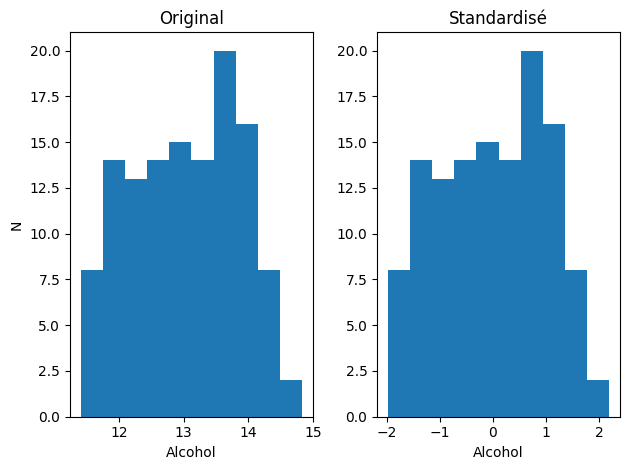

In [0]:
import matplotlib.pyplot as plt
plt.figure(1)
plt.subplot(121)
plt.hist(X_train[:,0])
plt.title('Original')
plt.xlabel('Alcohol')
plt.ylabel('N')

plt.subplot(122)
plt.hist(X_train_std[:,0])
plt.title('Standardisé')
plt.xlabel('Alcohol')

plt.tight_layout()
plt.show()

## Sélection des variables prédictives

### Régularisation L1

- Effet de la régularisation L1
> On étudie ici l'effet sur un modèle de type régression logistique par balayage de plusieurs valeurs du paramètre de régularisation (inverse) C

In [0]:
# ajouté avec dernière maj pour éviter message UndefinedMetricWarning dans les résultats affichés
from sklearn.exceptions import UndefinedMetricWarning
import warnings
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

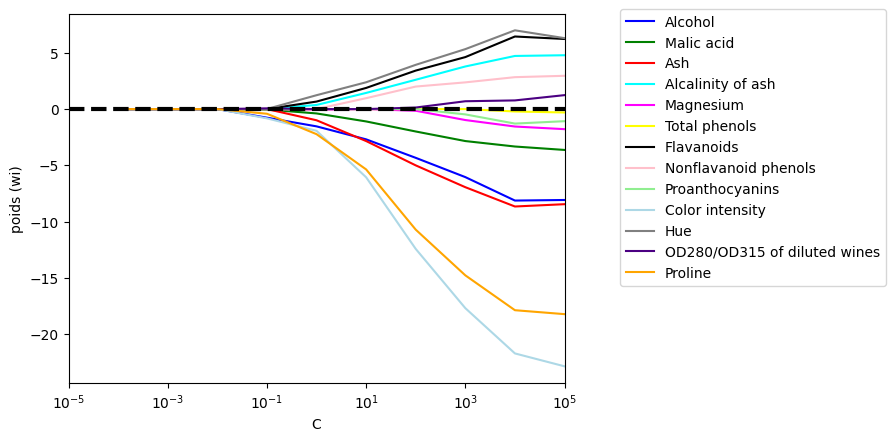

In [0]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import numpy as np
    
weights, params = [], []
for c in np.arange(-4., 6.):
    lr = LogisticRegression(penalty='l1', C=10.**c, 
                            solver='liblinear', multi_class='ovr', random_state=0)
    lr.fit(X_train_std, y_train)
    weights.append(lr.coef_[1])
    params.append(10**c)

weights = np.array(weights)


# Affichage graphique des résultats
fig = plt.figure()
ax = plt.subplot(111)

colors = ['blue', 'green', 'red', 'cyan', 
          'magenta', 'yellow', 'black', 
          'pink', 'lightgreen', 'lightblue', 
          'gray', 'indigo', 'orange']

# zip(*iterables) => returns an iterator of tuples
# range(stop) => retuns an iterable from 0 to stop - 1
for column, color in zip(range(weights.shape[1]), colors):
    plt.plot(params, weights[:, column],
             label=df_wine.columns[column + 1],
             color=color)
plt.axhline(0, color='black', linestyle='--', linewidth=3)
plt.xlim([10**(-5), 10**5])
plt.ylabel('poids (wi)')
plt.xlabel('C')
plt.xscale('log')
plt.legend(loc='upper center', 
          bbox_to_anchor=(1.38, 1.03),
          ncol=1, fancybox=True)
plt.show()

*Remarque : C, par convention dans scikit learn, est l'inverse du coefficient de régularisation*

- Impact sur la précision du modèle
  - sans régularisation :

In [0]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(C=10**5, solver='liblinear', multi_class='ovr')
lr.fit(X_train_std, y_train)
print('Training accuracy:', lr.score(X_train_std, y_train))
print('Test accuracy:', lr.score(X_test_std, y_test))
lr.intercept_, lr.coef_

Training accuracy: 1.0
Test accuracy: 1.0


(array([ -7.0437396 , -10.00444806, -12.08055378]),
 array([[  7.30910375,   3.00572468,   5.44412026,  -8.14375053,
           1.69365568,   0.1832975 ,   4.45871968,  -0.60370504,
          -0.07315505,  -1.59648458,  -0.57192421,   4.8413109 ,
           7.12409582],
        [ -8.84329368,  -3.39336804,  -9.19566699,   4.73718907,
           1.20020698,  -1.83615862,   7.37752696,   4.42199404,
          -1.82227058, -16.84405178,   6.45448459,   1.94463382,
         -15.79259774],
        [  4.4567311 ,   0.88953146,   3.79413293,   1.13569971,
          -1.1014228 ,   1.6592615 , -11.02570976,  -3.1050095 ,
          -2.32541537,   8.3531069 ,  -6.05011091,  -5.23168605,
           2.44635125]]))

*Remarque : il y a trois $w_0$ car il y a trois classes (l'algorithme exécute OvR pour choisir la bonne classe)*

- Impact sur la précision du modèle
> Avec régularisation L1

In [0]:
lr = LogisticRegression(solver='liblinear', multi_class='ovr', penalty='l1', C=0.1)
lr.fit(X_train_std, y_train)
print('Training accuracy:', lr.score(X_train_std, y_train))
print('Test accuracy:', lr.score(X_test_std, y_test))
lr.intercept_, lr.coef_

Training accuracy: 0.9596774193548387
Test accuracy: 0.9814814814814815


(array([-0.3187092 , -0.09902874, -0.81389185]),
 array([[ 0.2194811 ,  0.        ,  0.        ,  0.        ,  0.        ,
          0.        ,  0.54253448,  0.        ,  0.        ,  0.        ,
          0.        ,  0.        ,  1.51471365],
        [-0.76605689, -0.04060421,  0.        ,  0.        ,  0.        ,
          0.        ,  0.        ,  0.        ,  0.        , -0.82387305,
          0.00709737,  0.06468776, -0.41600909],
        [ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
          0.        , -0.74280318,  0.        ,  0.        ,  0.42936215,
         -0.31945595, -0.52031246,  0.        ]]))

*On voit bien l'effet matrice creuse bénéfique de la régularisation L1 ici avec préservation des performances et réduction des risques d'overfit*

### SBS
*Remarque : scikit learn possède une classe d'outils qui réalise ce type d'algorithme, ici à titre d'exemple, on montre cependant comment on peut écrire une classe ad-hoc d'outil de transformation telle la mise en oeuvre d'un SBS (Sequential Backward Selection)*

- écriture d'une classe dédiée au calcul

In [0]:
from sklearn.base import clone
from itertools import combinations
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


class SBS():
    def __init__(self, estimator, k_features = 1, scoring=accuracy_score,
                 test_size=0.3, random_state=0):
        self.scoring = scoring
        self.estimator = clone(estimator)
        self.k_features = k_features
        self.test_size = test_size
        self.random_state = random_state

    def fit(self, X, y):
        
        X_train, X_test, y_train, y_test = train_test_split(X, y, 
                            test_size=self.test_size,
                            random_state=self.random_state)
        
        dim = X_train.shape[1]
        self.indices_ = tuple(range(dim))
        self.subsets_ = [self.indices_]
        score = self._calc_score(X_train, y_train, 
                                 X_test, y_test, self.indices_)
        self.scores_ = [score]

        while dim > self.k_features:
            scores = []
            subsets = []

            for p in combinations(self.indices_, r=dim - 1):
                score = self._calc_score(X_train, y_train, 
                                         X_test, y_test, p)
                scores.append(score)
                subsets.append(p)

            best = np.argmax(scores)
            self.indices_ = subsets[best]
            self.subsets_.append(self.indices_)
            dim -= 1

            self.scores_.append(scores[best])
        self.k_score_ = self.scores_[-1]

        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test

        return self

    def transform(self, X):
        return X[:, self.indices_]

    def _calc_score(self, X_train, y_train, X_test, y_test, indices):
        self.estimator.fit(X_train[:, indices], y_train)
        y_pred = self.estimator.predict(X_test[:, indices])
        score = self.scoring(y_test, y_pred)
        return score

- application au jeu de données pour un modèle de type kNN

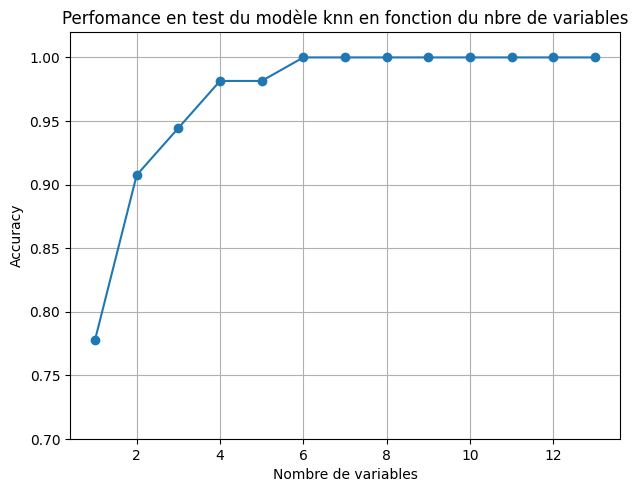

In [0]:
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

n_neighbors=5
knn = KNeighborsClassifier(n_neighbors=n_neighbors)

# Analyse séquentielle via SBS
sbs = SBS(knn, test_size=0.3, random_state=0)
X_std = sc.transform(X)
sbs.fit(X_std, y) # Rq le tirage train-test se fait lors de l'appel du SBS

# Analyse de la performance en fonction du nombre de variables
k_feat = [len(k) for k in sbs.subsets_]

plt.plot(k_feat, sbs.scores_, marker='o')
plt.ylim([0.7, 1.02])
plt.ylabel('Accuracy')
plt.xlabel('Nombre de variables')
plt.grid()
plt.tight_layout()
plt.title('Perfomance en test du modèle knn en fonction du nbre de variables')
# plt.savefig('images/04_08.png', dpi=300)
plt.show()

- détails des index des colonnes sélectionnées selon leur nombre

In [0]:
sbs.subsets_

[(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12),
 (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12),
 (0, 1, 2, 3, 4, 5, 6, 8, 9, 10, 12),
 (0, 1, 2, 3, 4, 5, 6, 8, 9, 12),
 (0, 1, 2, 3, 4, 5, 6, 8, 9),
 (0, 1, 2, 3, 4, 6, 8, 9),
 (0, 1, 2, 3, 6, 8, 9),
 (0, 2, 3, 6, 8, 9),
 (0, 2, 3, 6, 8),
 (0, 2, 3, 6),
 (0, 2, 6),
 (0, 6),
 (6,)]

- Test du modèle pour un nombre donné de colonnes sélectionnées

In [0]:
# test avec 4 colonnes
n_select = 4

# run
indices_ = sbs.subsets_[-n_select]
knn_ = KNeighborsClassifier(n_neighbors=n_neighbors)
knn_.fit(X_train_std[:,indices_], y_train)

print('Perf Train : ',knn_.score(X_train_std[:,indices_], y_train))
print('Perf Test  : ',knn_.score(X_test_std[:,indices_], y_test))

Perf Train :  0.9758064516129032
Perf Test  :  0.9259259259259259


### Feature importance (arbres)
- méthode qui utilise les *feature_importance* récupérables après entraînement d'un arbre ou d'une forêt)

- entraînement d'un RF

In [0]:
from sklearn.ensemble import RandomForestClassifier
forest = RandomForestClassifier(n_estimators=10, random_state=1, n_jobs=-1)
forest.fit(X_train, y_train)

RandomForestClassifier(n_estimators=10, n_jobs=-1, random_state=1)

- affichage des importances relatives des variables : table

In [0]:
import numpy as np
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]
feat_labels = df_wine.columns[1:]

plot_data = []
for f in range(X_train.shape[1]):
    cur = (feat_labels[indices[f]], importances[indices[f]])
    plot_data.append(cur)
    print("%2d) %-*s %f" % (f + 1, 30,
                            feat_labels[indices[f]],
                            importances[indices[f]])
         )

 1) Proline                        0.238783
 2) Color intensity                0.167705
 3) Flavanoids                     0.152091
 4) OD280/OD315 of diluted wines   0.107452
 5) Total phenols                  0.064552
 6) Magnesium                      0.051593
 7) Proanthocyanins                0.049217
 8) Alcohol                        0.046372
 9) Hue                            0.043385
10) Alcalinity of ash              0.034256
11) Malic acid                     0.026822
12) Ash                            0.011887
13) Nonflavanoid phenols           0.005886


- affichage des importances relatives des variables : histogramme

Text(0.5, 0, 'attributs')

<Figure size 640x480 with 0 Axes>

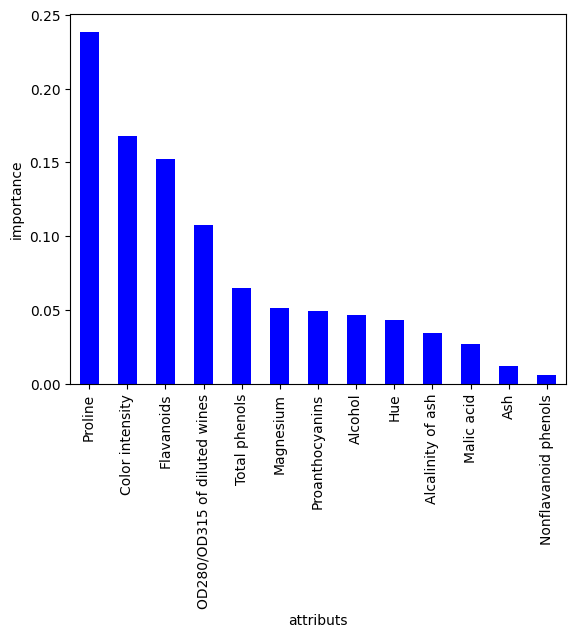

In [0]:
import matplotlib.pyplot as plt
labels = ['wine_attribute', 'importance']
plot_df = pd.DataFrame.from_records(plot_data, columns=labels)
plot_df_sort = plot_df.sort_values(by='importance', ascending=False)

# utilisation des fonctions de visualisation de pandas
plt.figure()
ax = plot_df_sort.plot.bar(x='wine_attribute', y='importance', 
                           legend=False, color='blue')
ax.set_ylabel("importance")
ax.set_xlabel("attributs")

- selection automatique des variables prédictives
  - par exemple si on fixe le seuil à 0.1, alors on peut s'attendre à 4 variables extraites cf le graphe ci-dessus.

In [0]:
from sklearn.feature_selection import SelectFromModel
sfm = SelectFromModel(forest, threshold=0.1, prefit=True)
X_feat = sfm.transform(X) # le faire sur X absolument et pas le X_train ici
      
for f in range(X_feat.shape[1]):
    print("%2d) %-*s %f" % (f + 1, 30, 
                            feat_labels[indices[f]], 
                            importances[indices[f]]))

 1) Proline                        0.238783
 2) Color intensity                0.167705
 3) Flavanoids                     0.152091
 4) OD280/OD315 of diluted wines   0.107452


Si l'on restreint l'entrainement sur ces  4 paramètres :

In [0]:
X_feat_train, X_feat_test, y_train, y_test = train_test_split(
    X_feat, y, 
    test_size=0.3, 
    random_state=0, 
    stratify=y)

forest.fit(X_feat_train, y_train)
print('Training accuracy:', forest.score(X_feat_train, y_train))
print('Test accuracy:', forest.score(X_feat_test, y_test))

Training accuracy: 0.9919354838709677
Test accuracy: 0.9814814814814815


### Shapley Values - SHAP

#### Approche agnostique
- sur le RandomForest

In [0]:
# Reprise du dataset
X, y = df_wine.iloc[:, 1:], df_wine.iloc[:, 0]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.3, 
    random_state=0, 
    stratify=y)

  0%|          | 0/54 [00:00<?, ?it/s]

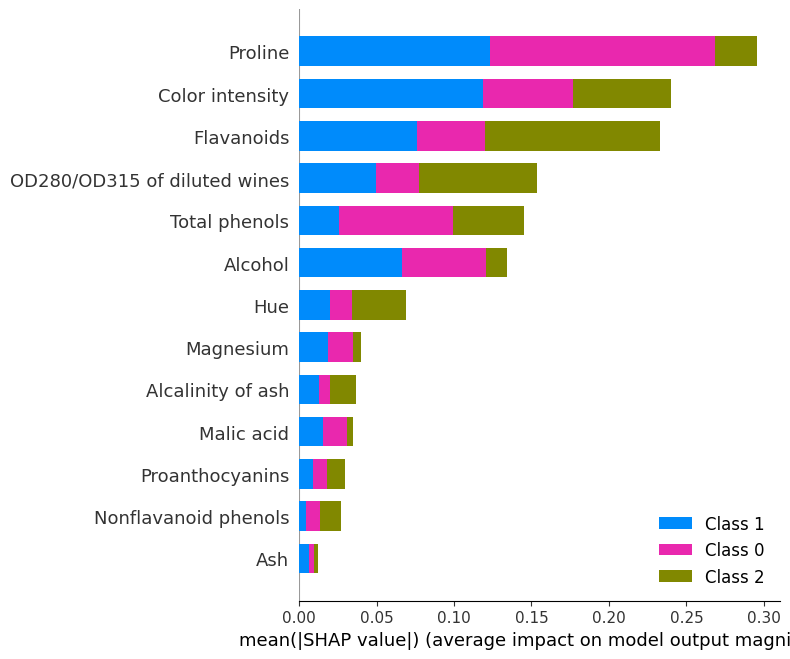

In [0]:
# instanciation du modèle forest
forest = RandomForestClassifier(n_estimators=10, random_state=1, n_jobs=-1)
forest.fit(X_train, y_train)

# SHAP KernelExplainer (agnostique)
explainer = shap.KernelExplainer(forest.predict_proba, X_train)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")

#### Interprétation

In [0]:
shap_values.shape

(54, 13, 3)

In [0]:
def show_explanation(indice_producteur=0):
    print(f"\n## Diagramme de densité pour le producteur {indice_producteur+1} (class={indice_producteur}) ##\n")
    shap.summary_plot(shap_values[:,:,indice_producteur], X_test, plot_type="violin")


## Diagramme de densité pour le producteur 1 (class=0) ##



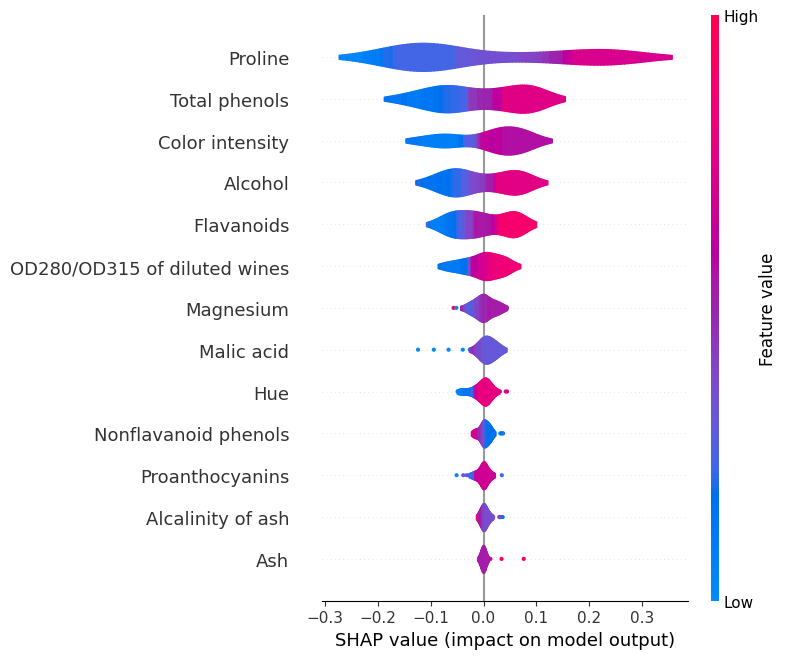

In [0]:
show_explanation(0)


## Diagramme de densité pour le producteur 2 (class=1) ##



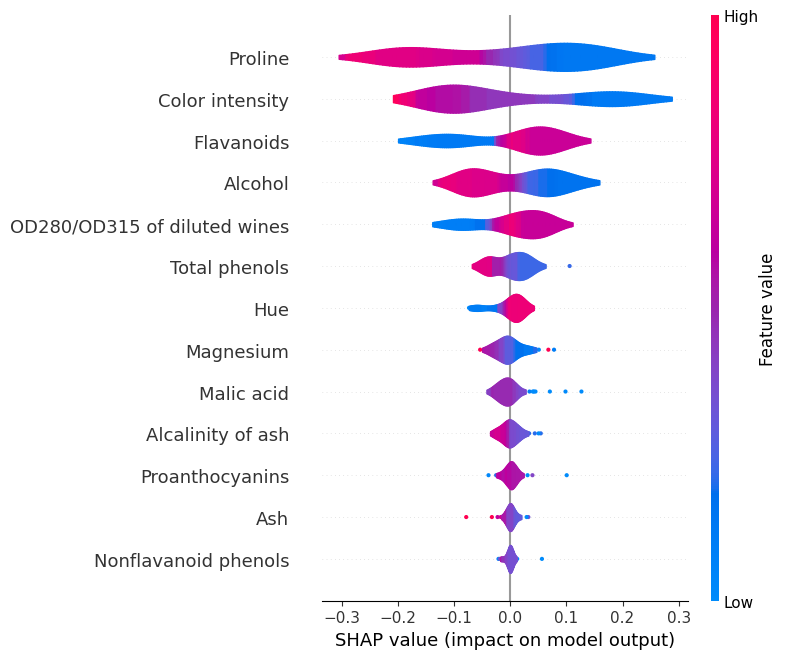

In [0]:
show_explanation(1)


## Diagramme de densité pour le producteur 3 (class=2) ##



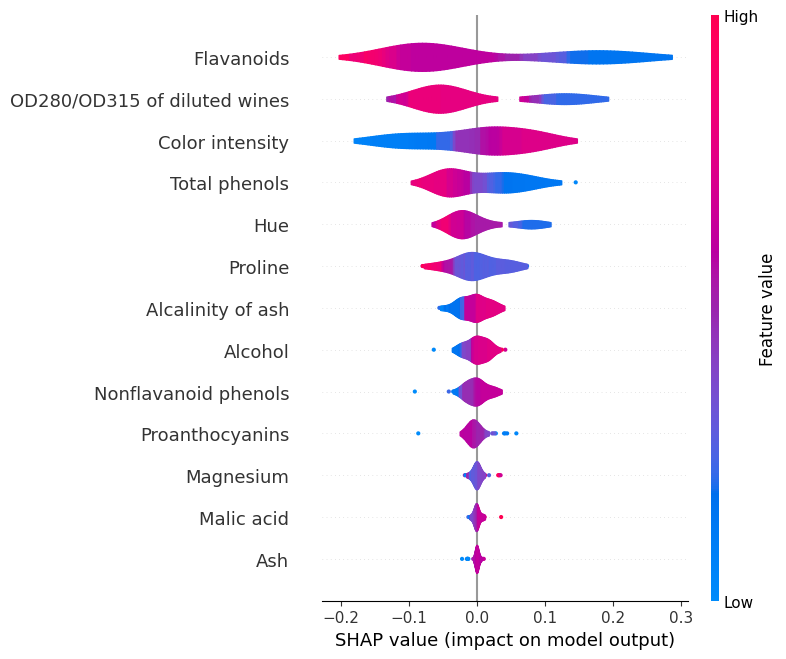

In [0]:
show_explanation(2)